In [12]:
# Add relevant Jupyter notebook extensions 
import sys
sys.path.append("..")

In [13]:
# Double-checking python path and data file existence
import os
print(os.getcwd())                             # should end in "notebooks"
print(os.path.exists("../data/mission.csv"))   # should print True

c:\Users\georg\OneDrive - Nexus365\3rd Year\B1 Computation\b1-coding-practical-mt24\notebooks
True


# Simulate closed-loop
Simulating code with control functionality and plotting the result with random disturbances: 

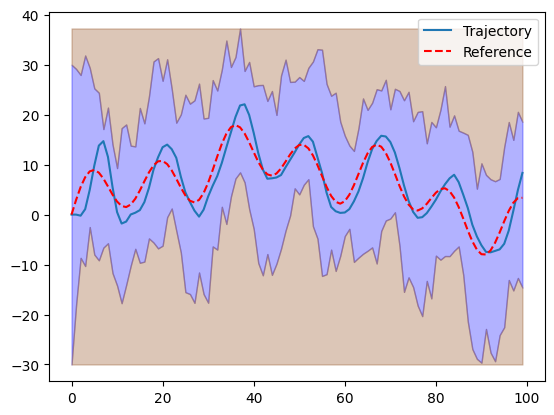

In [14]:
# Import relevant modules
import numpy as np
from uuv_mission.dynamic import Submarine, ClosedLoop, Mission
from uuv_mission.control import PDController

# Create a closed-loop simulation of the submarine following a mission
sub = Submarine()
closed_loop = ClosedLoop(sub, PDController())
mission = Mission.from_csv("../data/mission.csv") 


np.random.seed(2026) # Set a specific random seed for reproducibility
trajectory = closed_loop.simulate_with_random_disturbances(mission)
trajectory.plot_completed_mission(mission)

### Make Plot 
Add axis labels, another legend entry and title for clarity

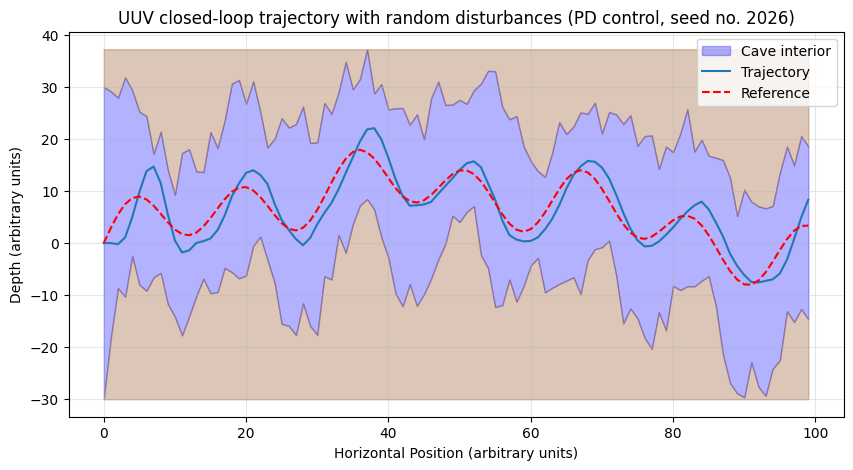

In [15]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(len(mission.reference))

plt.figure(figsize=(10, 5))
plt.fill_between(x, mission.cave_height, mission.cave_depth, color="blue", alpha=0.3, label="Cave interior")
plt.fill_between(x, mission.cave_depth, np.min(mission.cave_depth), color="saddlebrown", alpha=0.3)
plt.fill_between(x, np.max(mission.cave_height), mission.cave_height, color="saddlebrown", alpha=0.3)
plt.plot(trajectory.position[:, 0], trajectory.position[:, 1], label="Trajectory")
plt.plot(mission.reference, "r--", label="Reference")

plt.xlabel("Horizontal Position (arbitrary units)")
plt.ylabel("Depth (arbitrary units)")
plt.title("UUV closed-loop trajectory with random disturbances (PD control, seed no. 2026)")
plt.legend(loc="upper right")
plt.grid(alpha=0.3)
plt.savefig("../trajectory.png", dpi=200, bbox_inches="tight")  # for the report appendix

plt.show()